In [77]:
import colour
from colour.plotting import *

import solarpy as sp
import pandas as pd
import numpy as np
from numpy import pi, exp, sqrt, sin, cos, tan, arccos
from datetime import datetime, timedelta

from scipy.constants import h, c, k
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import matplotlib
from matplotlib import rc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Circle, Rectangle
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)

In [78]:
### load datasets

# sun radiation spectral quantities from "Preetham et al. - A Practical Analytic Model for Daylight (Appendix A.6, Table 2)"
data0 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S0.txt')
data1 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S1.txt')
data2 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/S2.txt')
data3 = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/SUN.txt')

lam = data0[:,0] # wavelength spectrum

S0  = data0[:,1] # scattering 0. sun radiation mean spectral radiant power (wavelength (nm, ?))
S1  = data1[:,1] # scattering 1
S2  = data2[:,1] # scattering 2
SUN  = data3[:,1]

# photopic limunosity from www.cvrl.org, "CIE Photopic V(λ) modified by Judd (1951) and Vos (1978) [also known as CIE VM(λ)]", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
photopic = pd.read_csv('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/vljve.csv',skiprows=0,na_values = ['0'])
photopic_array = photopic.to_numpy()
photopic_V = photopic_array[:,1]

# scotopic limunosity from www.cvrl.org, "CIE (1951) Scotopic V'(λ)", (wavelength (nm), luminous effiency (energy)) (380-780 nm in 5 nm steps)
scotopic = pd.read_csv('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/scvle.csv',skiprows=0,na_values = ['0'])
scotopic_array = scotopic.to_numpy()
scotopic_V = scotopic_array[:,1]

# the CIE colour matching function for 380 - 780 nm in 10 nm intervals
cmf = np.loadtxt('/Users/canartun/Documents/Research/Sundowning Syndrome/Datasets/cie-cmf.txt', usecols=(1,2,3))

### City - Latitude Dictionaries

In [79]:
### matching cities with latitudes

latitude_city = {39.9: "Ankara",
                 55.7: "Moscow",
                 52  : "Berlin",
                 51.5: "London",
                 41  : "Istanbul",
                 32.8: "Tripoli",
                 30  : "Cairo",
                 25  : "Sicily",
                -33.9: "Cape Town"}

city_latitude = {"Ankara"   : 39.9,
                 "Moscow"   : 55.7,
                 "Berlin"   : 52,
                 "London"   : 51.5,
                 "Istanbul" : 41,
                 "Tripoli"  : 32.8,
                 "Cairo"    : 30,
                 "Sicily"   : 25,
                 "Cape Town":-33.9}

### Functions

/var/folders/32/673tg56j78z17x_xgzpjgqh80000gn/T/ipykernel_75025/350001115.py:5: RuntimeWarning: overflow encountered in exp
  intensity = 2 * h * c**2 / (lam_m**5 * (np.exp(fac) - 1))


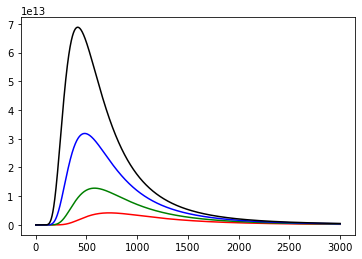

In [6]:
def planck(lam, T):
    
    lam_m = lam * 1e-9
    fac = h * c / (lam_m * k * T)
    intensity = 2 * h * c**2 / (lam_m**5 * (np.exp(fac) - 1))
    
    return intensity


# generate x-axis in increments from 1nm to 3 micrometer in 1 nm increments
# starting at 1 nm to avoid wav = 0, which would result in division by zero.
wavelengths = np.arange(1, 3e3, 1) 

# intensity at 4000K, 5000K, 6000K, 7000K
intensity4000 = planck(wavelengths, 4000.)
intensity5000 = planck(wavelengths, 5000.)
intensity6000 = planck(wavelengths, 6000.)
intensity7000 = planck(wavelengths, 7000.)


plt.plot(wavelengths, intensity4000, 'r-') 
# plot intensity4000 versus wavelength in nm as a red line
plt.plot(wavelengths, intensity5000, 'g-') # 5000K green line
plt.plot(wavelengths, intensity6000, 'b-') # 6000K blue line
plt.plot(wavelengths, intensity7000, 'k-') # 7000K black line

# show the plot
plt.show()

In [80]:
### matrices and vectors from "Preetham et al. - A Practical Analytic Model for Daylight" (Appendix A.2)
A1 = [[ 0.1787,-1.4630],
      [-0.3554, 0.4275],
      [-0.0227, 5.3251],
      [ 0.1206,-2.5771],
      [-0.0670, 0.3703]]
    
A2 = [[-0.0193,-0.2592],
      [-0.0665, 0.0008],
      [-0.0004, 0.2125],
      [-0.0641,-0.8989],
      [-0.0033, 0.0452]]
    
A3 = [[-0.0167,-0.2608],
      [-0.0950, 0.0092],
      [-0.0079, 0.2102],
      [-0.0441,-1.6537],
      [-0.0109, 0.0529]]

xz_matrix = [[ 0.0017,-0.0037, 0.0021, 0.0000],
             [-0.0290, 0.0638,-0.0320, 0.0039],
             [ 0.1169,-0.2120, 0.0605, 0.2589]]
    
yz_matrix = [[ 0.0028,-0.0061, 0.0032, 0.0000],
             [-0.0421, 0.0897,-0.0415, 0.0052],
             [ 0.1535,-0.2676, 0.0667, 0.2669]]


def xyz_from_xy(x, y):
    
    return np.array((x, y, 1-x-y))

class ColourSystem:
    
    # the CIE colour matching function for 380 - 780 nm in 10 nm intervals
    # cmf = np.loadtxt('/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Datasets/cie-cmf.txt', usecols=(1,2,3))
        
    def __init__(self, red, green, blue, white):
        
        # chromaticities
        self.red, self.green, self.blue = red, green, blue
        self.white = white
        
        # the chromaticity matrix (rgb -> xyz) and its inverse
        self.M = np.vstack((self.red, self.green, self.blue)).T 
        self.MI = np.linalg.inv(self.M)
        
        # white scaling array
        self.wscale = self.MI.dot(self.white)
        
        # xyz -> rgb transformation matrix
        self.T = self.MI / self.wscale[:, np.newaxis]
    
    def xyz_to_rgb(self, xyz, out_fmt=None):
        
        rgb = self.T.dot(xyz)
        
        if np.any(rgb < 0):
            # we're not in the RGB gamut: approximate by desaturating
            w = - np.min(rgb)
            rgb += w
            
        if not np.all(rgb == 0):
            # normalize the rgb vector
            rgb /= np.max(rgb)
        
        if out_fmt == 'html':
            return self.rgb_to_hex(rgb)
        
        return rgb
        
    def rgb_to_hex(self, rgb):
        
        hex_rgb = (255*rgb).astype(int)
        
        return '#{:02x}{:02x}{:02x}'.format(*hex_rgb)

    def spec_to_xyz(self, spec):
        
        XYZ = np.sum(spec[:, np.newaxis] * cmf, axis=0)
        den = np.sum(XYZ)
        if den == 0.:
            return XYZ
        
        return XYZ / den
    
    def spec_to_rgb(self, spec, out_fmt=None):
        
        xyz = self.spec_to_xyz(spec)
        
        return self.xyz_to_rgb(xyz, out_fmt)


illuminant_D65 = xyz_from_xy(0.3127, 0.3291)

cs_hdtv = ColourSystem(red   = xyz_from_xy(0.67, 0.33),
                       green = xyz_from_xy(0.21, 0.71),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)

cs_smpte = ColourSystem(red   = xyz_from_xy(0.63, 0.34),
                        green = xyz_from_xy(0.31, 0.595),
                        blue  = xyz_from_xy(0.155,0.070),
                        white = illuminant_D65)

cs_srgb = ColourSystem(red   = xyz_from_xy(0.64, 0.33),
                       green = xyz_from_xy(0.30, 0.60),
                       blue  = xyz_from_xy(0.15, 0.06),
                       white = illuminant_D65)


cs = cs_hdtv # choose color matching system (cs_hdtv, cs_smpte, cs_srgb)


def planck(lam, T):

    lam_m = lam / 1e9
    fac = h*c/lam_m/k/T
    B = 2*h*c**2/lam_m**5 / (np.exp(fac)-1)
    
    return B


def vision_throughout_the_day(date, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180)
    phi_v   = phi_viewer*(pi/180)
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
    
    T_vector = [turbidity**2, turbidity, 1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date+timedelta(minutes=m),latitude)
        phi_s = sp.solar_azimuth(date+timedelta(minutes=m),latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        #for i in range(len(SD)):
        #    if SD[i] < 0:
        #        SD[i] = S0[i]
        #    else: pass
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        vision_sc.append(sum(scotopic_vision))
        vision_pc.append(sum(photopic_vision))
        vision.append((sum(scotopic_vision)+sum(photopic_vision)))
        
    #time_scale = [i/60 for i in range(0,1440,10)]
    time_scale = [date+timedelta(minutes=i) for i in range(0, 6*10*24, 10)]
    
    return time_scale, vision_sc, vision_pc, vision



def vision_at_a_moment(moment, latitude, altitude, turbidity, theta_viewer, phi_viewer):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
        
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
        
    T_vector = [turbidity**2,turbidity,1]
    
    theta_s = sp.theta_z(moment,latitude)
    phi_s = sp.solar_azimuth(moment,latitude)
    
    gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
    
    Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
    Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
    
    theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
    
    xz = np.dot(T_vector,xz_matrix)
    xz = np.dot(xz, theta_s_vector)
    
    yz = np.dot(T_vector,yz_matrix)
    yz = np.dot(yz, theta_s_vector)
    
    
    FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
    FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
    Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
    Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
    Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
    Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
    
    Y = Yz*(FY_theta_gamma/FY_0_theta_s)
    x = xz*(Fx_theta_gamma/Fx_0_theta_s)
    y = yz*(Fy_theta_gamma/Fy_0_theta_s)
    
    M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
    M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
    
    SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2) # the relative spectral radiant power
    
    #for i in range(len(SD)):
    #    if SD[i] < 0:
    #        SD[i] = S0[i]
    #    else: pass
    
    scotopic_vision = SD*scotopic_V
    photopic_vision = SD*photopic_V
    
    return SD, scotopic_vision, photopic_vision



def sky_view(date, latitude, altitude, turbidity, theta_viewer, phi_viewer, spectrum, size):
    
    ### the observer's viewing angle
    theta_v = theta_viewer*(pi/180) # off-zenith angle in radians (zenith=0, horizon=90)
    phi_v = phi_viewer*(pi/180) # azimuthal angle in radians (east=-90, south=0, west=90, north=-180)
    

    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
     
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    fig, ax = plt.subplots(figsize=size)
    for i in range(144):
    
        m = 10*i
        
        theta_s = sp.theta_z(date+timedelta(minutes=m),latitude)
        phi_s = sp.solar_azimuth(date+timedelta(minutes=m),latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V   
        
        # plot the desired spectrum
        if   spectrum == 'SD'      : html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        elif spectrum == 'scotopic': html_rgb = cs.spec_to_rgb(scotopic_vision, out_fmt='html')
        elif spectrum == 'photopic': html_rgb = cs.spec_to_rgb(photopic_vision, out_fmt='html')
        elif spectrum == 'total'   : html_rgb = cs.spec_to_rgb(scotopic_vision+photopic_vision, out_fmt='html')
        else: print("Choose the spectrum!")
        
        x_coordinate, y_coordinate = i%6, -(i//6)
        #patch = Circle(xy=(x_coordinate,y_coordinate*2), radius=0.5, fc=html_rgb)
        patch = Rectangle(xy=(x_coordinate,y_coordinate*2), width=0.98, height=1.8, fc=html_rgb)
        ax.add_patch(patch)
        
        seconds = timedelta(minutes=m).seconds//60 # H:M formatter
        minutes = seconds//60
        seconds %= 60
        ax.annotate("%02i:%02i"%(minutes,seconds), xy=(x_coordinate,y_coordinate*2), xytext=(x_coordinate+0.35,y_coordinate*2+0.5), color='black')
        
    ax.set_xlim(-0.1, 6.07)
    ax.set_ylim(-47, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')
    
    #ax.set_aspect("equal")
    
    plt.title("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+", in "+latitude_city[latitude]+".", fontsize=15)
    
    plt.show()
    #fig.savefig(r"/Users/canartun/OneDrive/RESEARCH/SUNDOWNING SYNDROME/Results/Sky_View/SkyView_"+latitude_city[latitude]+"_"+spectrum+".png", format='png', bbox_inches='tight')

    return print("View for the "+spectrum+" spectrum on "+str(date.day)+"."+str(date.month)+"."+str(date.year)+".")


def panoramic_sky_view(time, city, altitude, turbidity, theta_range_viewer, phi_range_viewer):
    
    latitude = city_latitude[city]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
 
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    patch_color = []
    
    theta_difference = abs(theta_range_viewer[1]-theta_range_viewer[0])
    phi_difference = abs(phi_range_viewer[1]-phi_range_viewer[0])

    tt = theta_range_viewer[0]
    angle = []
    for i in range(theta_difference+1):
        pp = phi_range_viewer[0]
        for j in range(phi_difference+1):
            angle.append((tt,pp))
            pp += 1
        tt += 1
    
    n = (theta_difference+1)*(phi_difference+1)
    
    for i in range(n):
        
        theta_v = angle[i][0]*(pi/180)
        phi_v = angle[i][1]*(pi/180)
        
        theta_s = sp.theta_z(time,latitude)
        phi_s = sp.solar_azimuth(time,latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V
        
        html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        patch_color.append(html_rgb)
    
    return patch_color

In [82]:
### computations

# fig (a)

time = datetime(2023, 10, 29, 7, 30)
city = "Ankara"
alt, tur = 25, 2
Theta_v_range = (10,89)   # (zenith=0, horizon=90)
Phi_v_range   = (-70,10) # (east=-90, south=0, west=90, north=-180)
xaxis_limit, yaxis_limit = (-2,83), (-81,3)

patch_colors = panoramic_sky_view(time, city, alt, tur, Theta_v_range, Phi_v_range)

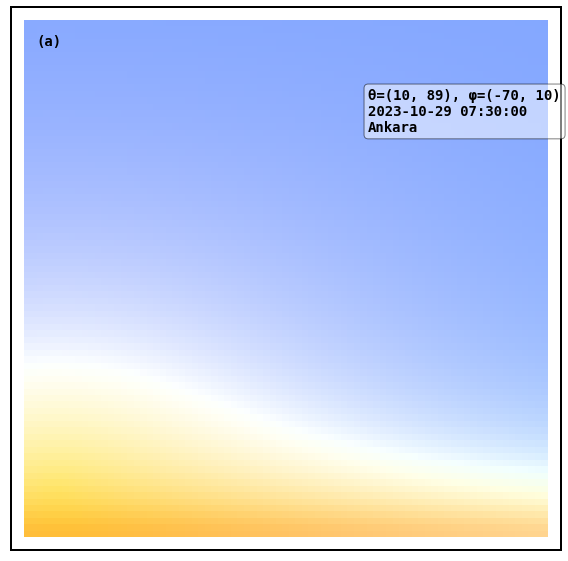

In [83]:
# plot

fig, ax = plt.subplots(figsize=(10,10))

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax.add_patch(patch)
        
ax.set_aspect("equal")
ax.set_xlim(xaxis_limit)
ax.set_ylim(yaxis_limit)
ax.set_xticks([])
ax.set_yticks([])
ax.set_facecolor('white')

props = dict(boxstyle='round', facecolor='white', alpha=0.5)
ax.text(0.65, 0.85, "\u03B8="+str(Theta_v_range)+", \u03C6="+str(Phi_v_range)+"\n"+str(time)+"\n"+city, transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

ax.text(2,-3, "(a)", fontsize=14)

#plt.title("Panoramic view of the sky in range \u03B8="+str(theta_range_viewer)+",\n\u03C6="+str(phi_range_viewer)+", on "+str(time)+", in "+city+".", fontsize=16)  #+"."+str(time.month)+"."+str(time.year)+", in "+city[latitude]+"."     
    
plt.show()

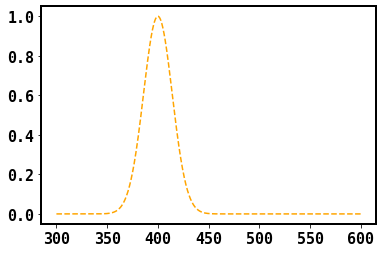

In [122]:
def f(x, a):
    return np.exp(-((x-400)/a)**2)

xspace = np.linspace(300, 600, 1000)
plt.plot(xspace, f(xspace, 20), ls="--", color="orange")

In [126]:
def fit_function(x, A, alpha, B, beta, sigma):
    
    return A * x**3 / (np.exp(alpha * x) - 1) + B * np.exp(-((x - beta)/sigma)**2)

In [57]:
def fit_function(x, A, alpha, b):
    
    return A * np.exp(alpha * (x - b)**2)

In [53]:
def fit_function(x, A, beta, B, mu, sigma):
    
    #return A*x**3 / (np.exp(alpha * x) - 1) + 
    #return A * np.exp(alpha * (x - b)**2)
    return (A * np.exp(-x/beta) + B * np.exp(-1.0 * (x - mu)**2 / (2 * sigma**2)))

In [65]:
def fit_function(x, A, alpha, B, beta):
    
    return A * x**3 / (np.exp(alpha * x) - 1)  +  (B * np.exp(-x / beta))

Optimal parameters = 3.86259199741e-05 0.00755979237423 -121.043193422 333.623674065 68.453872952



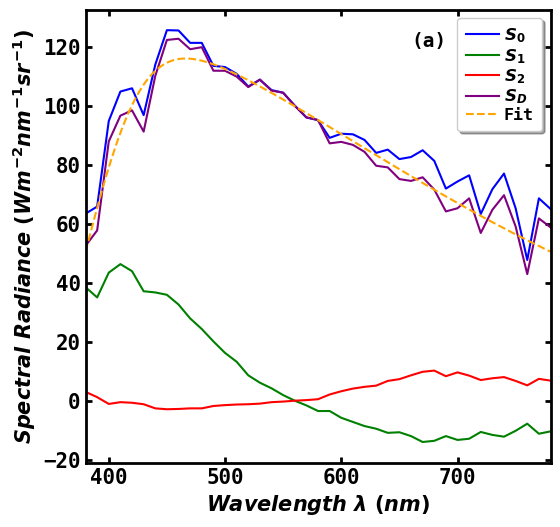

In [143]:
# fig (b)

time = datetime(2023, 10, 29, 7, 50)
lat = city_latitude["Ankara"]
alt, tur = 25, 2
Theta_v = 80
Phi_v   = 0

SD, _, _ = vision_at_a_moment(time, lat, alt, tur, Theta_v, Phi_v)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 6), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

#ax = plt.subplot(111)
ax.plot(lam, S0, color='blue', label="$S_0$")
ax.plot(lam, S1, color='green', label="$S_1$")
ax.plot(lam, S2, color='red', label="$S_2$")
ax.plot(lam, SD, color="purple", label="$S_D$")
#ax.plot(lam, planck(lam, 5778) * 1e-10, color="yellow", label="BB")

params0 = [.001, .01, 100, 400, 10] # initial guess for the parameters
popts, pcov = curve_fit(f=fit_function, xdata=lam, ydata=SD, p0=params0, sigma=None, full_output=False)
print("Optimal parameters =", *popts, end="\n\n")
xspace = np.linspace(min(lam), max(lam), 1000)
ax.plot(xspace, fit_function(xspace, *popts), ls="--", color="orange", label="Fit")
ax.set_xlim(380, 780)

ax.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax.legend(loc=0, prop={'size':12},  ncol=1, frameon=True, fancybox=True, shadow=True, borderpad=0.5, handletextpad=0.3, borderaxespad=0.5, labelspacing=0.1, columnspacing=0.1)
ax.set_xlabel("$Wavelength \ \lambda \ (nm)$")
ax.set_ylabel("$Spectral \ Radiance \ (Wm^{-2}nm^{-1}sr^{-1})$")
ax.text(660,120, "(a)", fontsize=14)

plt.show()

In [ ]:
time = datetime(2023, 10, 29, 7, 50)
city = "Ankara"
alt, tur = 25, 2
Theta_v_range = (10,89)   # (zenith=0, horizon=90)
Phi_v_range   = (-70,10) # (east=-90, south=0, west=90, north=-180)
xaxis_limit, yaxis_limit = (-2,83), (-81,3)

In [14]:
# fig (c): The spectral luminous efficacy for human vision

day = [datetime(2023, 10, 29)]

lat = city_latitude["Ankara"]
alt, tur = 25, 2

Theta_v = 80 # (zenith=0, horizon=90)
Phi_v   = 0 # (east=-90, south=0, west=90, north=180)

t, Vsc, Vpc, V  = vision_throughout_the_day(day[0], lat, alt, tur, Theta_v, Phi_v)

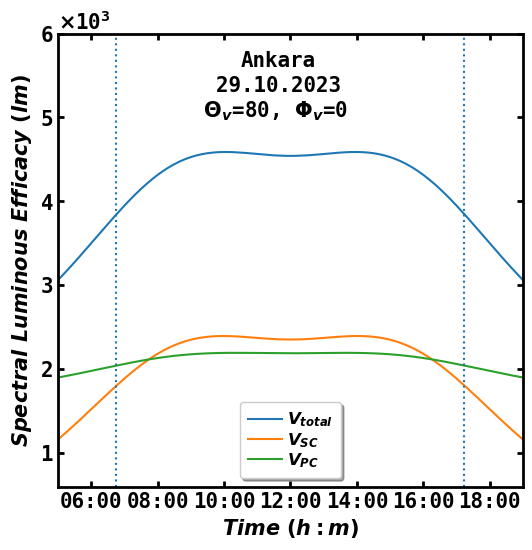

In [8]:
# plot 

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 6), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

ax.plot(t, V,   label="$V_{total}$")
ax.plot(t, Vsc, label="$V_{SC}$")
ax.plot(t, Vpc, label="$V_{PC}$")

myFmt = mdates.DateFormatter('%H:%M')
ax.xaxis.set_major_formatter(myFmt)

ax.set_xlim(t[30], t[-30])
ax.set_ylim(.6e3, 6e3)
#ax.xaxis.set_ticks([0, 0.3, 0.6, 0.9])

ax.legend(loc=0, prop={'size':12},  ncol=1, frameon=True, fancybox=True, shadow=True, borderpad=0.5, handletextpad=0.3, borderaxespad=0.5, labelspacing=0.1, columnspacing=0.1)

ax.set_xlabel("$Time \ (h:m)$", weight="bold")
ax.set_ylabel("$Spectral \ Luminous \ Efficacy \ (lm)$", weight="bold")

ax.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax.ticklabel_format(axis='y', style="sci", useMathText=True, useOffset=True, useLocale=False, scilimits=(0,0))

plt.axvline(sp.sunrise_time(day[0],lat), ls=':')
plt.axvline(sp.sunset_time(day[0],lat),  ls=':')

ax.text(t[63], 5600, latitude_city[lat])
ax.text(t[54], 5000, "  "+str(day[0].day)+"."+str(day[0].month)+"."+str(day[0].year)+
                   "\n $\Theta_v$="+str(np.round(Theta_v, 3))+", $\Phi_v$="+str(np.round(Phi_v, 3)),
                   family="monospace", weight="bold")

#ax.text(t[35],5500, "(c)", fontsize=14)

################################################ inset (c)
#ax_inset = ax.inset_axes([0.5,0.6, 0.5,0.4])

#lamda = np.arange(380.,751.,10)
#blackbody_dist = planck(lamda, 5778)
#ax_inset.plot(lamda, a)
#ax_inset.plot(lamda, blackbody_dist)

plt.show()

In [26]:
PATH = "/Users/canartun/Desktop/ssabance_fine.csv"
df_cone = pd.read_csv(PATH, sep=",", names=["wavelength", "L-cone", "M-cone", "S-cone"])
df_cone.head()

,wavelength,L-cone,M-cone,S-cone
0,390.0,-0.93379,-1.04790,-0.13385
1,390.1,-0.93284,-1.04679,-0.13310
2,390.2,-0.93190,-1.04568,-0.13233
3,390.3,-0.93096,-1.04457,-0.13156
4,390.4,-0.93003,-1.04346,-0.13079


In [27]:
PATH = "/Users/canartun/Desktop/sucrodsh.csv"
df_rod = pd.read_csv(PATH, sep=",", names=["wavelength", "rod"])
df_rod.head()

,wavelength,rod
0,379,-0.888
1,390,-0.602
2,398,-0.784
3,410,-0.605
4,418,-0.496


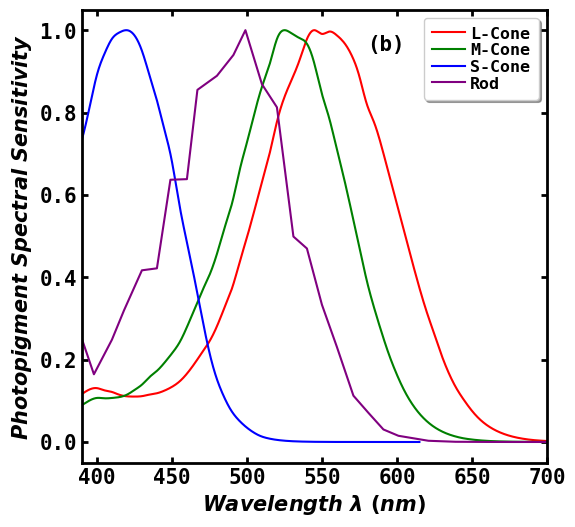

In [146]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 6), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

ax.plot(df_cone["wavelength"], 10**df_cone["L-cone"], color="r", label="L-Cone")
ax.plot(df_cone["wavelength"], 10**df_cone["M-cone"], color="g", label="M-Cone")
ax.plot(df_cone["wavelength"], 10**df_cone["S-cone"], color="b", label="S-Cone")
ax.plot(df_rod["wavelength"], 10**df_rod["rod"], color="purple", label="Rod")
ax.set_xlim(390, 700)
ax.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax.legend(loc=0, prop={'size':12},  ncol=1, frameon=True, fancybox=True, shadow=True, borderpad=0.5, handletextpad=0.3, borderaxespad=0.5, labelspacing=0.1, columnspacing=0.1)
ax.set_xlabel("$Wavelength \ \lambda \ (nm)$", weight="bold")
ax.set_ylabel("$Photopigment \ Spectral \ Sensitivity$", weight="bold")
ax.text(580, .95, "(b)")

plt.show()

In [34]:
# fig (d)

day = datetime(2023, 10, 29)

moment = [timedelta(minutes=60* 8.5),
          timedelta(minutes=60* 12),
          timedelta(minutes=60* 14),
          timedelta(minutes=60* 17)]

lat = city_latitude["Ankara"]
alt, tur = 25, 2

Theta_v = 80
Phi_v   = 0


S_d_1, V_sc_1, V_pc_1 = vision_at_a_moment(day+moment[0],lat,alt,tur,Theta_v,Phi_v)
S_d_2, V_sc_2, V_pc_2 = vision_at_a_moment(day+moment[1],lat,alt,tur,Theta_v,Phi_v)
S_d_3, V_sc_3, V_pc_3 = vision_at_a_moment(day+moment[2],lat,alt,tur,Theta_v,Phi_v)
S_d_4, V_sc_4, V_pc_4 = vision_at_a_moment(day+moment[3],lat,alt,tur,Theta_v,Phi_v)

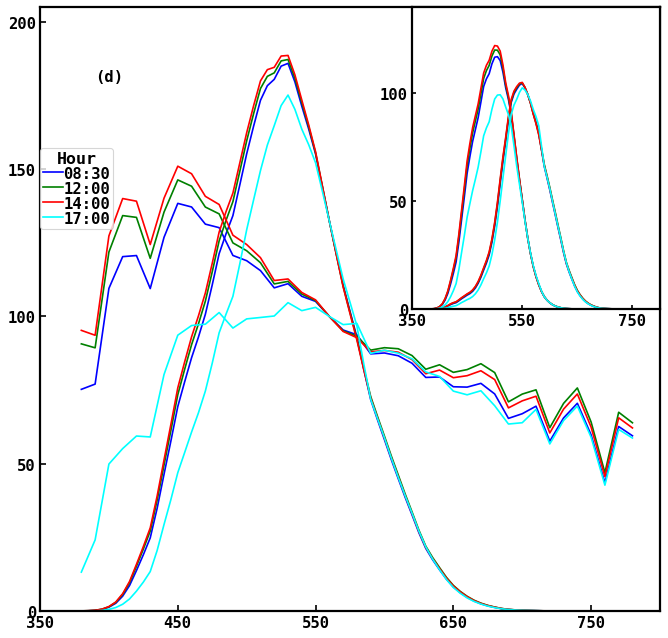

In [35]:
# plot

sizeoffonts = 14
color = ['blue', 'green', 'red', 'aqua', 'black', 'pink']

fig = plt.figure(figsize=(10,10), dpi=80)

ax1 = plt.subplot(111)

ax1.plot(lam, S_d_1,  color=color[0])
V_tot_1 = V_sc_1+V_pc_1
seconds = moment[0].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60                   #
ax1.plot(lam, V_tot_1, label="%02i:%02i"%(minutes,seconds), color=color[0])
#for i in range(len(V_tot1_1)):
#    if V_tot1_1[i] == max(V_tot1_1):
#        plt.axvline(lam[i], ls=':')
#        break
#    else: pass
        
ax1.plot(lam, S_d_2, color=color[1])
V_tot_2 = V_sc_2+V_pc_2
seconds = moment[1].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60                   #
ax1.plot(lam, V_tot_2,  label="%02i:%02i"%(minutes,seconds), color=color[1])

ax1.plot(lam, S_d_3, color=color[2])
V_tot_3 = V_sc_3+V_pc_3
seconds = moment[2].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.plot(lam, V_tot_3, label="%02i:%02i"%(minutes,seconds), color=color[2])

ax1.plot(lam, S_d_4, color=color[3])
V_tot_4 = V_sc_4+V_pc_4
seconds = moment[3].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.plot(lam, V_tot_4,  label="%02i:%02i"%(minutes,seconds), color=color[3])
    
ax1.set_xlim(350, 800)
ax1.set_ylim(0, 205)
ax1.xaxis.set_ticks([350, 450, 550, 650, 750])
ax1.yaxis.set_ticks([0, 50, 100, 150, 200])
#ax1.set_xticks([])
#ax1.set_yticks([])
ax1.tick_params(axis="both", direction="in", width=1.5, length=5, labelsize=sizeoffonts)

ax1.legend(loc='center left',
          ncol=1,
          bbox_to_anchor=(0,0.7),
          prop={'size':sizeoffonts},
          title="Hour",
          columnspacing=.2,
          labelspacing=0,
          handlelength=1.3,
          handletextpad=0.,
          borderpad=0.2,
          borderaxespad=0)


################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc_1, color=color[0])
ax1_inset.plot(lam, V_pc_1, color=color[0])
ax1_inset.plot(lam, V_sc_2, color=color[1])
ax1_inset.plot(lam, V_pc_2, color=color[1])
ax1_inset.plot(lam, V_sc_3, color=color[2])
ax1_inset.plot(lam, V_pc_3, color=color[2])
ax1_inset.plot(lam, V_sc_4, color=color[3])
ax1_inset.plot(lam, V_pc_4, color=color[3])
ax1_inset.axis([350,800, 0,140])
ax1_inset.xaxis.set_ticks([350, 550, 750])
ax1_inset.yaxis.set_ticks([0, 50, 100])
ax1_inset.tick_params(axis="both", direction="in", width=1.5, length=4, labelsize=sizeoffonts)

ax1.text(390,180, "(d)", fontsize=14)

plt.show()

In [127]:
day = datetime(2023, 10, 29)

moment = [timedelta(minutes=60* 12),
          timedelta(minutes=60* 15),
          timedelta(minutes=60* 17.5)]

lat = city_latitude["Ankara"]
alt, tur = 25, 2

Theta_v = 80
Phi_v   = 0


S_d_1, V_sc_1, V_pc_1 = vision_at_a_moment(day+moment[0],lat,alt,tur,Theta_v,Phi_v)
S_d_2, V_sc_2, V_pc_2 = vision_at_a_moment(day+moment[1],lat,alt,tur,Theta_v,Phi_v)
S_d_3, V_sc_3, V_pc_3 = vision_at_a_moment(day+moment[2],lat,alt,tur,Theta_v,Phi_v)

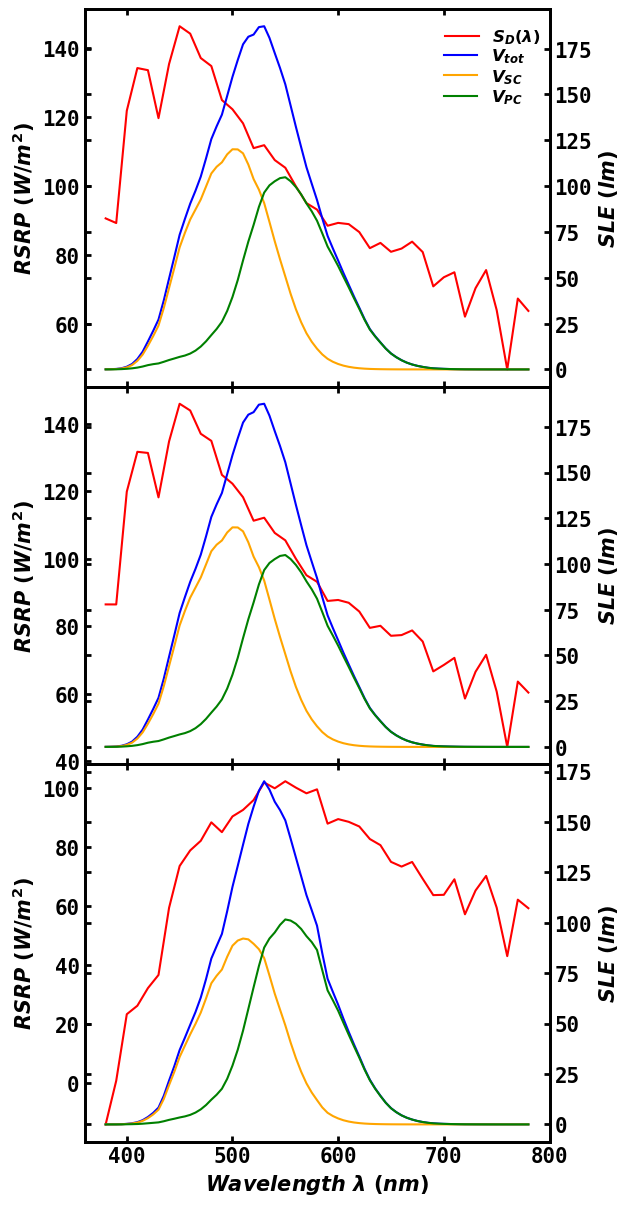

In [128]:
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(6, 15), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

#fig.text(0.5, 0.04, "$Wavelength \ \lambda \ (nm)$", ha='center')
#fig.text(0.02, 0.5, "$?$", va='center', rotation='vertical')

# upper
ax1 = plt.subplot(311)
ax1.plot(lam, S_d_1,  color="r", label="$S_D(\lambda)$")
ax1.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax1.set_xticklabels([])
ax1.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
ax1.legend(loc=1, bbox_to_anchor=(1.013, 0.99), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax1r = ax1.twinx()
V_tot_1 = V_sc_1 + V_pc_1
ax1r.plot(lam, V_tot_1,  color="blue", label="$V_{tot}$")
ax1r.plot(lam, V_sc_1,  color="orange", label="$V_{SC}$")
ax1r.plot(lam, V_pc_1,  color="green", label="$V_{PC}$")
ax1r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax1r.set_xticklabels([])
ax1r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
ax1r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

# middle
ax2 = plt.subplot(312)
ax2.plot(lam, S_d_2,  color="r", label="$S_D(\lambda)$")
ax2.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax2.set_xticklabels([])
#ax2.set_xlabel(r"$Wavelength \ \lambda \ (nm)$", weight="bold")
ax2.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
#ax2.legend(loc=1, bbox_to_anchor=(1.013, 0.99), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax2r = ax2.twinx()
V_tot_2 = V_sc_2 + V_pc_2
ax2r.plot(lam, V_tot_2,  color="blue", label="$V_{tot}$")
ax2r.plot(lam, V_sc_2,  color="orange", label="$V_{SC}$")
ax2r.plot(lam, V_pc_2,  color="green", label="$V_{PC}$")
ax2r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax2r.set_xticklabels([])
ax2r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
#ax2r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

# lower
ax3 = plt.subplot(313)
ax3.plot(lam, S_d_3,  color="r", label="$S_D(\lambda)$")
ax3.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax3.set_xlabel(r"$Wavelength \ \lambda \ (nm)$", weight="bold")
ax3.set_ylabel(r"$RSRP \ (W/m^2)$", weight="bold")
#ax3.legend(loc=1, bbox_to_anchor=(1.013, 0.99), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

ax3r = ax3.twinx()
V_tot_3 = V_sc_3 + V_pc_3
ax3r.plot(lam, V_tot_3,  color="blue", label="$V_{tot}$")
ax3r.plot(lam, V_sc_3,  color="orange", label="$V_{SC}$")
ax3r.plot(lam, V_pc_3,  color="green", label="$V_{PC}$")
ax3r.tick_params(axis="both", direction="in", bottom=True, top=True, left=True, right=True, width=2, length=4)
ax3r.set_ylabel(r"$SLE \ (lm)$", weight="bold")
#ax3r.legend(loc=1, bbox_to_anchor=(0.98, 0.94), prop={'size':12},  ncol=1, frameon=False, labelspacing=0.1)

#seconds = moment[2].seconds//60 # H:M formatter for plot label
#minutes = seconds//60           #
#seconds %= 60   
#ax3.text(710, 90, "%02i:%02i" % (minutes,seconds))

plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

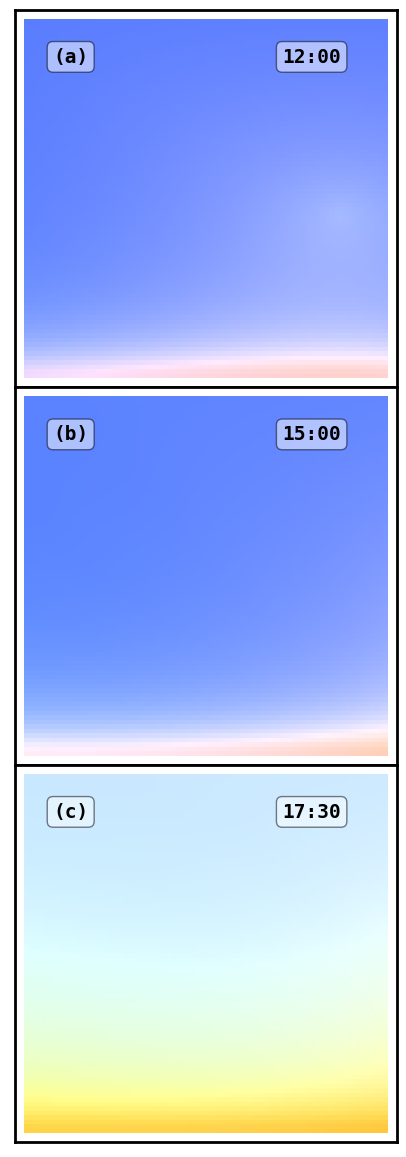

In [129]:
city = "Ankara"
alt, tur = 25, 2
Theta_v_range = (10, 89)   # (zenith=0, horizon=90)
Phi_v_range   = (-70, 10) # (east=-90, south=0, west=90, north=-180)
xaxis_limit, yaxis_limit = (-2, 83), (-81, 3)

# plot
fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(6, 15), dpi=100)
fig.set_facecolor("white")
plt.rc(group="font", family="monospace", weight="bold", size=15)
plt.rc(group="lines", linewidth=1.5)
plt.rc(group="axes", linewidth=2)

# upper
ax1 = plt.subplot(311)
time = datetime(2023, 10, 29, 12, 0)
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax1.add_patch(patch)
ax1.set_aspect("equal")
ax1.set_xlim(xaxis_limit)
ax1.set_ylim(yaxis_limit)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_facecolor('white')
seconds = moment[0].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax1.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax1.transAxes, fontsize=14, verticalalignment='top', bbox=props)
ax1.text(0.1, 0.9, "(a)", transform=ax1.transAxes, fontsize=14, verticalalignment='top', bbox=props)


# middle
ax2 = plt.subplot(312)
time = datetime(2023, 10, 29, 15, 0)
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax2.add_patch(patch)
ax2.set_aspect("equal")
ax2.set_xlim(xaxis_limit)
ax2.set_ylim(yaxis_limit)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_facecolor('white')
seconds = moment[1].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax2.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax2.transAxes, fontsize=14, verticalalignment='top', bbox=props)
ax2.text(0.1, 0.9, "(b)", transform=ax2.transAxes, fontsize=14, verticalalignment='top', bbox=props)


# lower
ax3 = plt.subplot(313)
time = datetime(2023, 10, 29, 17, 30)
patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate,y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax3.add_patch(patch)
ax3.set_aspect("equal")
ax3.set_xlim(xaxis_limit)
ax3.set_ylim(yaxis_limit)
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_facecolor('white')
seconds = moment[2].seconds//60 # H:M formatter for plot label
minutes = seconds//60           #
seconds %= 60   
ax3.text(0.7, 0.9, "%02i:%02i" % (minutes,seconds), transform=ax3.transAxes, fontsize=14, verticalalignment='top', bbox=props)
ax3.text(0.1, 0.9, "(c)", transform=ax3.transAxes, fontsize=14, verticalalignment='top', bbox=props)

plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

In [ ]:
a = []
for i in range(len(SUN)):
    a.append(SUN[i]*1e9)
a

[16559000000000.0,
 16233700000000.0,
 21127500000000.0,
 25888200000000.0,
 25829100000000.0,
 24232300000000.0,
 26760500000000.0,
 29658300000000.0,
 30545400000000.0,
 30057500000000.0,
 30663700000000.0,
 28830400000000.0,
 28712100000000.0,
 27825000000000.0,
 27100600000000.0,
 27233600000000.0,
 26361300000000.0,
 25503800000000.0,
 25060200000000.0,
 25311600000000.0,
 25355900000000.0,
 25134200000000.0,
 24631500000000.0,
 24173200000000.0,
 23685300000000.0,
 23212100000000.0,
 22827700000000.0,
 22339800000000.0,
 21970200000000.0,
 21526700000000.0,
 21097900000000.0,
 20728300000000.0,
 20240400000000.0,
 19870800000000.0,
 19427200000000.0,
 19072400000000.0,
 18628900000000.0,
 18259200000000.0]

In [96]:
from astropy.modeling import models
from astropy import units as u
bb = models.BlackBody(temperature=5000*u.K)
bb(6000 * u.AA)

<Quantity 1.5325468511395068e-05 erg / (cm2 Hz s sr)>

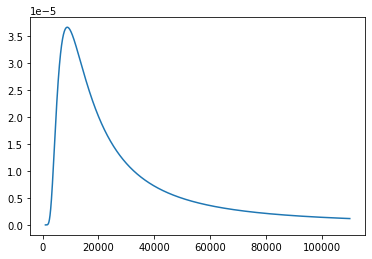

In [100]:
from astropy.modeling.models import BlackBody
from astropy import units as u
from astropy.visualization import quantity_support

bb = BlackBody(temperature=5778*u.K)
wav = np.arange(1000, 110000) * u.AA
flux = bb(wav)

plt.plot(wav, flux)
#with quantity_support():
#    plt.figure()
#    plt.semilogx(wav, flux)
#    plt.axvline(bb.nu_max.to(u.AA, equivalencies=u.spectral()).value, ls='--')
#    plt.show()

In [60]:
blackbody_sd = colour.sd_blackbody(5778, colour.SpectralShape(10, 10000, 10))

sd_ASTMG173_ETR = colour.plotting.SD_ASTMG173_ETR.copy()

sd_ASTMG173_ETR.interpolate(colour.SpectralShape(interval=5), interpolator=colour.LinearInterpolator)

sd_ASTMG173_ETR /= np.max(savgol_filter(sd_ASTMG173_ETR.values, 101, 3))
sd_ASTMG173_ETR *= np.max(np.nan_to_num(blackbody_sd.values))

ax_inset.colour.plotting.plot_multi_sds([sd_ASTMG173_ETR, blackbody_sd],
                               **{'title': 'The Sun - Blackbody 5778K','y_label': 'W / (sr m$^2$) / m'})



/Users/canartun/.local/lib/python3.8/site-packages/colour/utilities/verbose.py:237: ColourUsageWarning: For consistency reasons, the unit of the planckian radiator spectral distribution values has been changed from "W/sr/m^2/m" to "W/sr/m^2/nm".
They are now multiplied by 1e-9. Note that this only affects computations requiring absolute quantities.
See https://github.com/colour-science/colour/issues/559 for more background information.
  warn(*args, **kwargs)


AttributeError: 'Axes' object has no attribute 'colour'

In [47]:
s = sd_ASTMG173_ETR
s

SpectralDistribution([[  280.        ,  1136.35546305],
                      [  285.        ,  2437.48246824],
                      [  290.        ,  7802.05031337],
       ..., 
                      [ 3990.        ,   121.67318251],
                      [ 3995.        ,   120.56454303],
                      [ 4000.        ,   120.28738316]],
                     interpolator=LinearInterpolator,
                     interpolator_kwargs={},
                     extrapolator=Extrapolator,
                     extrapolator_kwargs={'method': 'Constant', 'left': None, 'right': None})

In [54]:
colour.plotting.SD_ASTMG173_ETR
sd_ASTMG173_ETR.interpolate(
    colour.SpectralShape(interval=5), interpolator=colour.LinearInterpolator)


SpectralDistribution([[  280.        ,  1136.35546305],
                      [  285.        ,  2437.48246824],
                      [  290.        ,  7802.05031337],
       ..., 
                      [ 3990.        ,   121.67318251],
                      [ 3995.        ,   120.56454303],
                      [ 4000.        ,   120.28738316]],
                     interpolator=LinearInterpolator,
                     interpolator_kwargs={},
                     extrapolator=Extrapolator,
                     extrapolator_kwargs={'method': 'Constant', 'left': None, 'right': None})

NameError: name 'S_d1_1' is not defined

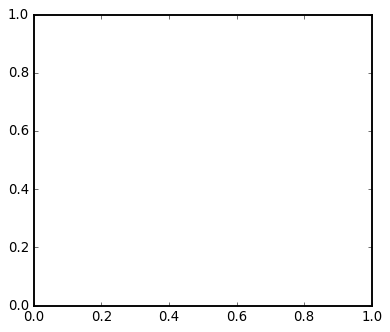

In [61]:
### plot - fig.2

plt.style.use('classic')
linewidth = 1.7
sizeoffonts = 15
rc('lines', linewidth=1.5)
rc('axes', linewidth=linewidth)
rc('legend', labelspacing=0,
             handlelength=0,
             handletextpad=-0.1,
             columnspacing=-0.1,
             borderpad=0.1,
             borderaxespad=0.2,
             fontsize=sizeoffonts-2)

fig = plt.figure(figsize=(12,10), dpi=80)
fig.set_facecolor('none')
#fig.text(0.04, 0.5, "$\mathrm{Spectral}$ $\mathrm{Radiant}$ $\mathrm{Power}$ $\mathrm{Density}$ $\mathrm{(W/m^2)}$", va='center', rotation='vertical', fontsize=sizeoffonts+5)
#fig.text(0.5, 0.02, "$\mathrm{Wavelength}$ $\mathrm{\lambda(nm)}$", ha='center', fontsize=sizeoffonts+5)

color = ['blue', 'green', 'red', 'aqua', 'black', 'pink']

###################################################################### figure (a)
ax1 = plt.subplot(221)
ax1.plot(lam, S_d1_1,  color=color[0])
#ax1.plot(lam, V_sc1_1, color=color[0])

################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc1_1, color=color[0])


###################################################################### figure (b)
ax1 = plt.subplot(222)
ax1.plot(lam, S_d1_1,  color=color[0])
#ax1.plot(lam, V_sc1_1, color=color[0])

################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc1_1, color=color[0])


###################################################################### figure (c)
ax1 = plt.subplot(223)
ax1.plot(lam, S_d1_1,  color=color[0])
#ax1.plot(lam, V_sc1_1, color=color[0])

################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc1_1, color=color[0])


###################################################################### figure (d)
ax1 = plt.subplot(224)
ax1.plot(lam, S_d1_1,  color=color[0])
#ax1.plot(lam, V_sc1_1, color=color[0])

################################################ inset (a)
ax1_inset = ax1.inset_axes([0.6,0.5, 0.4,0.5])
ax1_inset.plot(lam, V_sc1_1, color=color[0])




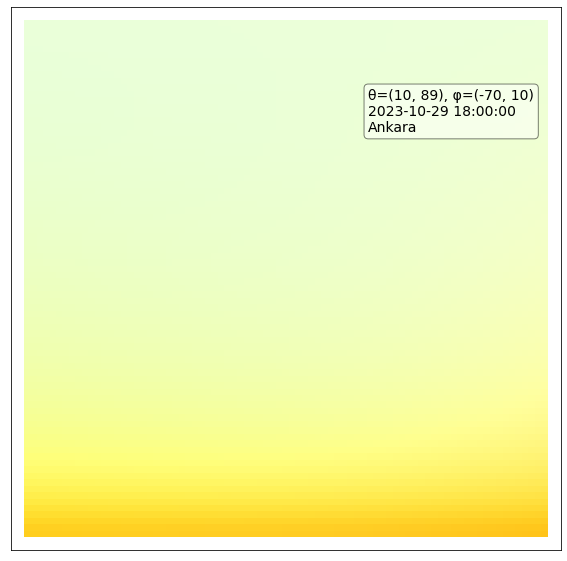

In [11]:
def panoramic_sky_view(time, city, altitude, turbidity, theta_range_viewer, phi_range_viewer):
    
    latitude = city_latitude[city]
    
    Y_coefficient = np.dot(A1, [turbidity,1]) # [Ay, By, Cy, Dy, Ey]
    x_coefficient = np.dot(A2, [turbidity,1]) # [xy, xy, xy, xy, xy]
    y_coefficient = np.dot(A3, [turbidity,1]) # [yy, yy, yy, yy, yy]
 
    T_vector = [turbidity**2,turbidity,1]
    
    vision = []
    vision_sc = []
    vision_pc = []
    
    patch_color = []
    
    theta_difference = abs(theta_range_viewer[1]-theta_range_viewer[0])
    phi_difference = abs(phi_range_viewer[1]-phi_range_viewer[0])

    tt = theta_range_viewer[0]
    angle = []
    for i in range(theta_difference+1):
        pp = phi_range_viewer[0]
        for j in range(phi_difference+1):
            angle.append((tt,pp))
            pp += 1
        tt += 1
    
    n = (theta_difference+1)*(phi_difference+1)
    
    for i in range(n):
        
        theta_v = angle[i][0]*(pi/180)
        phi_v = angle[i][1]*(pi/180)
        
        theta_s = sp.theta_z(time,latitude)
        phi_s = sp.solar_azimuth(time,latitude)
        
        gamma = arccos(cos(theta_v)*cos(theta_s) + sin(theta_v)*cos(phi_v)*sin(theta_s)*cos(phi_s) + sin(theta_v)*sin(phi_v)*sin(theta_s)*sin(phi_s))
        
        Chi = (4/9 - turbidity/120)*(pi - 2*theta_s)
        Yz = (4.0453*turbidity - 4.9710)*tan(Chi) - 0.2155*turbidity + 2.4192
        
        theta_s_vector = [theta_s**3,theta_s**2,theta_s,1]
        
        xz = np.dot(T_vector,xz_matrix)
        xz = np.dot(xz, theta_s_vector)
        
        yz = np.dot(T_vector,yz_matrix)
        yz = np.dot(yz, theta_s_vector)
        
        
        FY_theta_gamma = (1+Y_coefficient[0]*exp(Y_coefficient[1]/cos(theta_v))) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*gamma) + Y_coefficient[4]*(cos(gamma))**2)
        FY_0_theta_s = (1+Y_coefficient[0]*exp(Y_coefficient[1])) * (1+Y_coefficient[2]*exp(Y_coefficient[3]*theta_s) + Y_coefficient[4]*(cos(theta_s))**2)
        
        Fx_theta_gamma = (1+x_coefficient[0]*exp(x_coefficient[1]/cos(theta_v))) * (1+x_coefficient[2]*exp(x_coefficient[3]*gamma) + x_coefficient[4]*(cos(gamma))**2)
        Fx_0_theta_s = (1+x_coefficient[0]*exp(x_coefficient[1])) * (1+x_coefficient[2]*exp(x_coefficient[3]*theta_s) + x_coefficient[4]*(cos(theta_s))**2)
        
        Fy_theta_gamma = (1+y_coefficient[0]*exp(y_coefficient[1]/cos(theta_v))) * (1+y_coefficient[2]*exp(y_coefficient[3]*gamma) + y_coefficient[4]*(cos(gamma))**2)
        Fy_0_theta_s = (1+y_coefficient[0]*exp(y_coefficient[1])) * (1+y_coefficient[2]*exp(y_coefficient[3]*theta_s)+ y_coefficient[4]*(cos(theta_s))**2)
        
        
        Y = Yz*(FY_theta_gamma/FY_0_theta_s)
        x = xz*(Fx_theta_gamma/Fx_0_theta_s)
        y = yz*(Fy_theta_gamma/Fy_0_theta_s)
        
        M1 = (-1.3515-1.7703*x+5.9114*y)/(0.0241+0.2562*x-0.7341*y)
        M2 = (0.0300-31.4424*x+30.0717*y)/(0.0241+0.2562*x-0.7341*y)
        
        SD = np.array(S0) + M1*np.array(S1) + M2*np.array(S2)
        
        scotopic_vision = SD*scotopic_V
        photopic_vision = SD*photopic_V
        
        html_rgb = cs.spec_to_rgb(SD, out_fmt='html')
        patch_color.append(html_rgb)
    
    return patch_color


time = datetime(2023, 10, 29, 18, 0)
city = "Ankara"
alt, tur = 25, 2
Theta_v_range = (10,89)   # (zenith=0, horizon=90)
Phi_v_range   = (-70,10) # (east=-90, south=0, west=90, north=-180)
xaxis_limit, yaxis_limit = (-2,83), (-81,3)

patch_colors = panoramic_sky_view(time,city,alt,tur,Theta_v_range,Phi_v_range)

# plot
fig, ax = plt.subplots(figsize=(10,10))

theta_difference = abs(Theta_v_range[1]-Theta_v_range[0])
phi_difference = abs(Phi_v_range[1]-Phi_v_range[0])
n = (theta_difference+1)*(phi_difference+1)
for i in range(n):
        x_coordinate, y_coordinate = i%(phi_difference+1), -(i//(phi_difference+1))
        patch = Rectangle(xy=(x_coordinate, y_coordinate), width=1, height=1, fc=patch_colors[i])
        ax.add_patch(patch)
        
ax.set_aspect("equal")
ax.set_xlim(xaxis_limit)
ax.set_ylim(yaxis_limit)
ax.set_xticks([])
ax.set_yticks([])
ax.set_facecolor('white')

props = dict(boxstyle='round', facecolor='white', alpha=0.5)
ax.text(0.65, 0.85, "\u03B8="+str(Theta_v_range)+", \u03C6="+str(Phi_v_range)+"\n"+str(time)+"\n"+city, transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props)
    
plt.show()

In [ ]:
_